# Audio level simulation - front end and the audio on/off rules

**Author:** Konrad Jelen<br>
**Date:** 2026-10-17<br>
**Purpose:** establish what silence ("quiet") and music ("turned on") produce at the A1 pin of the Mk10 board, and test which off rule keeps audio on through quiet music while still turning it off after 10 minutes of silence

The board turns line-level audio into a slow DC level that the Nano samples every 51 ms. U1.1 (LM324A) amplifies by 101, U1.2 with D_PEAK rectifies, and the peak detector charges through 10 kΩ into 1 µF and discharges through 1 MΩ. The firmware averages 50 samples, starts audio when the average rises above the threshold T, and turns audio off after 10 minutes in which the average never rose above the off level.

- `frontend_model.py` holds the circuit model and a replica of the firmware decisions
- The replica is checked against the real firmware on simavr in section 8
- Music is modelled as band-limited pink noise under a wandering loudness envelope, at CD line level (0 dBFS = 2 V RMS)
- **Output:** `results/audio-level-simulation.json`, read by the explainer page

## Imports

One cell with every import. The simavr harness comes from `test/harness`, so its path is added before the import.

In [1]:
%load_ext autoreload
%autoreload 2

# Standard library
import json  # export for the explainer page
import sys  # path to the simavr harness
from pathlib import Path  # cache and result paths

# Numerics
import numpy as np  # signals, statistics
from scipy import signal  # analog frequency response

# Plotting
import matplotlib.pyplot as plt  # figures, OO API only

# Output
from rich import print as rprint  # one call per block of output
from rich.panel import Panel  # configuration render
from rich.progress import Progress  # long loops
from rich.table import Table  # result tables

# Project
import frontend_model as fm  # circuit model and firmware replica

sys.path.insert(0, str(Path.cwd().parent / "test" / "harness"))
import eeprom  # EEPROM image for the simulated board
import sim  # firmware.elf on simavr

## Reproducibility

Every random signal comes from a generator seeded from one value, so a re-run produces the same readings and the same verdicts.

In [2]:
SEED = 42  # base seed; scenario i uses SEED + i
rng = np.random.default_rng(SEED)

## Configuration

Board variants, listening scenarios, the thresholds under test and the off-rule designs, all in one cell. A scenario is a list of segments: silence, music at a level in dBFS with a wandering spread in dB, or a transient.

- **Board variants** - `typical` is the LM324A typical input bias current (20 nA) with 0.3 mV of mains hum; `worst` is the datasheet maximum (100 nA) with 1 mV of hum from a poor ground
- **Setups** - the default threshold 300, a threshold learned during loud music, and a threshold learned during quiet music
- **Designs** - the original firmware, the first proposal (off at T − σ, σ 10% until learned), the same with 25%, an off level at 25% of T, the simple design now in the firmware, and a quiet-based design

In [3]:
BOARDS = {  # LM324A input bias current and mains hum at the RCA input
    "typical": dict(ib=20e-9, hum_mv=0.3),
    "worst": dict(ib=100e-9, hum_mv=1.0),
    "ground loop": dict(ib=100e-9, hum_mv=3.0),
}
SCENARIOS = {  # segments: ("silence", s) | ("music", s, dBFS, spread dB) | ("click", V, decay s) | ("burst", s)
    "pop": dict(board="typical", learn={"loud": 50},
                segments=[("silence", 20), ("music", 210, -14, 4), ("silence", 2), ("music", 210, -14, 4),
                          ("silence", 2), ("music", 120, -14, 4), ("silence", 780)]),
    "classical": dict(board="typical", learn={"loud": 50, "quiet": 400},
                      segments=[("silence", 20), ("music", 300, -26, 6), ("music", 720, -52, 5),
                                ("music", 240, -20, 6), ("silence", 780)]),
    "late night": dict(board="typical", learn={"loud": 50, "quiet": 110},
                       segments=[("silence", 20), ("music", 60, -30, 4), ("music", 900, -56, 4), ("silence", 780)]),
    "clicks in silence": dict(board="typical", learn={},
                              segments=[("silence", 30), ("click", 0.5, 0.03), ("silence", 60), ("click", 2.0, 0.002),
                                        ("silence", 60), ("burst", 0.1), ("silence", 60)]),
    "late night, worst board": dict(board="worst", learn={"loud": 50, "quiet": 110},
                                    segments=[("silence", 20), ("music", 60, -30, 4), ("music", 900, -56, 4),
                                              ("silence", 780)]),
    "late night, ground loop": dict(board="ground loop", learn={"loud": 50, "quiet": 110},
                                    segments=[("silence", 20), ("music", 60, -30, 4), ("music", 900, -56, 4),
                                              ("silence", 780)]),
}
DEFAULT_T = 300  # AUDIOLEVEL_INIT_THRESHOLD
QUIET_AT = 15.0  # s; the quiet level is the idle average at this time, before any music
SIMPLE_MIN_T = 160  # simple design: lowest learned threshold, 4 x the worst quiet reading (35) plus margin
SETUPS = {"default": "default threshold 300", "loud": "learned on loud music", "quiet": "learned on quiet music"}
DESIGNS = {
    "original": "no hysteresis (original firmware)",
    "sigma10": "off at T - sigma, sigma 10% of T until learned (first proposal)",
    "sigma25": "off at T - sigma, sigma 25% of T until learned",
    "quarter": "off at 25% of T",
    "simple": "simple: learn sets T to half the music level (at least 160), off at 25% of T (in the firmware)",
    "quiet": "quiet-based: T halfway from quiet to music, off 25% of the way from quiet to T",
}
TRANSFER_DBFS = np.arange(-90, 1, 2.5)  # input levels for the transfer curve
VALIDATE = dict(scenario="pop")  # simavr check of the replica against the firmware design
COLORS = {"level": "#3498DB", "threshold": "#E74C3C", "on": "#2ECC71", "quiet": "#95A5A6", "sine": "#9B59B6"}
CACHE, RESULTS = Path("cache"), Path("results")
CACHE.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

fe = fm.FrontEnd()
rprint(Panel(
    f"[bold]Front end[/bold]\n"
    f"  VGND            [cyan]{fe.vgnd:.3f} V[/cyan] [dim](47k / 10k from 5 V)[/dim]\n"
    f"  Stage 1 gain    [cyan]{fe.gain:.0f}[/cyan] [dim]above {1 / (2 * np.pi * fe.r_amp2 * fe.c_amp2):.0f} Hz[/dim]\n"
    f"  Peak detector   [cyan]{fe.r_peak1 * fe.c_peak * 1e3:.0f} ms[/cyan] attack, [cyan]{fe.r_peak2 * fe.c_peak:.1f} s[/cyan] decay\n"
    f"  ADC             [cyan]{fm.ADC_PERIOD * 1e3:.0f} ms[/cyan] period, 10 bit on AVCC 5 V\n"
    f"[bold]Firmware[/bold]\n"
    f"  Average         [cyan]{fm.SAMPLES}[/cyan] samples\n"
    f"  Default T       [cyan]{DEFAULT_T}[/cyan]\n"
    f"  Standby         [cyan]{fm.STANDBY / 60:.0f} min[/cyan], restarted at most once per [cyan]{fm.CHECK / 60:.0f} min[/cyan]\n"
    f"[bold]Run[/bold]\n"
    f"  Scenarios       [cyan]{len(SCENARIOS)}[/cyan], setups [cyan]{len(SETUPS)}[/cyan], designs [cyan]{len(DESIGNS)}[/cyan]\n"
    f"  Seed            [cyan]{SEED}[/cyan]",
    title="Configuration"))

╭───────────────────────────────────────────────── Configuration ─────────────────────────────────────────────────╮
│ Front end                                                                                                       │
│   VGND            0.877 V (47k / 10k from 5 V)                                                                  │
│   Stage 1 gain    101 above 159 Hz                                                                              │
│   Peak detector   10 ms attack, 1.0 s decay                                                                     │
│   ADC             51 ms period, 10 bit on AVCC 5 V                                                              │
│ Firmware                                                                                                        │
│   Average         50 samples                                                                                    │
│   Default T       300                                                                                           │
│   Standby         10 min, restarted at most once per 1 min                                                      │
│ Run                                                                                                             │
│   Scenarios       6, setups 3, designs 6                                                                        │
│   Seed            42                                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Circuit model

Stage 1 is a non-inverting amplifier whose gain leg (1 kΩ in series with 1 µF) makes the gain frequency dependent:

$$G(s) = 1 + \frac{R_{AMP1}}{R_{AMP2} + 1/(s\,C_{AMP2})}$$

The gain is 1 at DC and 101 above 159 Hz. The input coupling (220 nF into 100 kΩ) adds a 7 Hz high-pass, and the LM324's 1.2 MHz gain-bandwidth limits the top to about 12 kHz. The figure shows the small-signal gain before clipping.

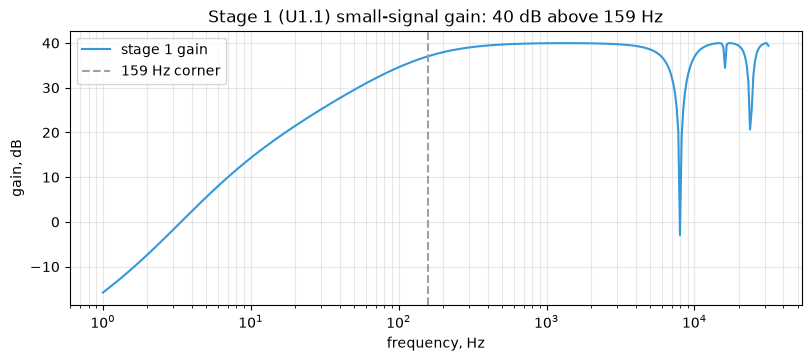

In [4]:
b, a = fm.stage1_filter(fe)
freqs = np.logspace(0, 4.5, 400)
_, response = signal.freqz(b, a, worN=freqs, fs=fm.FS)

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.semilogx(freqs, 20 * np.log10(np.abs(response)), color=COLORS["level"], label="stage 1 gain")
ax.axvline(159, color=COLORS["quiet"], linestyle="--", label="159 Hz corner")
ax.set_xlabel("frequency, Hz")
ax.set_ylabel("gain, dB")
ax.set_title("Stage 1 (U1.1) small-signal gain: 40 dB above 159 Hz")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

## What quiet means

With no music the reading is not zero. Two things hold it up: U1.2's input bias current flows out of the pin through R4 (1 MΩ), which puts $V = I_B \cdot R_4$ on the rectifier input, and mains hum at the RCA input is amplified about 31 times at 50 Hz. The cell measures the silent reading for the bias current and hum combinations a real board can have.

               Silent reading at A1, ADC counts               
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ input bias current ┃ hum 0.05 mV ┃ hum 0.3 mV ┃ hum 1.0 mV ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ 0 nA               │           0 │          5 │         16 │
│ 20 nA (typical)    │           4 │          8 │         20 │
│ 100 nA (maximum)   │          20 │         24 │         35 │
└────────────────────┴─────────────┴────────────┴────────────┘

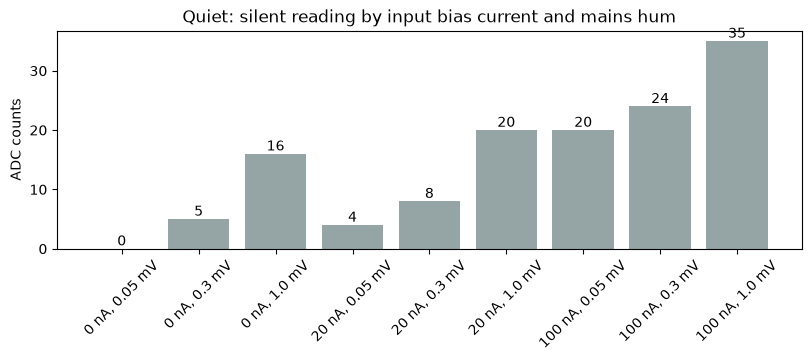

In [5]:
floor = []
for ib_na in (0, 20, 100):
    for hum in (0.05, 0.3, 1.0):
        circuit = fm.Circuit(fm.FrontEnd(ib=ib_na * 1e-9))
        source = fm.Source(np.random.default_rng(SEED), hum_mv=hum)
        volts = np.concatenate([circuit.feed(source.chunk(10)) for _ in range(3)])
        floor.append(dict(ib_na=ib_na, hum_mv=hum, counts=int(fm.adc(volts[-100:]).max())))

table = Table(title="Silent reading at A1, ADC counts")
table.add_column("input bias current")
for hum in (0.05, 0.3, 1.0):
    table.add_column(f"hum {hum} mV", justify="right")
for ib_na in (0, 20, 100):
    row = [f["counts"] for f in floor if f["ib_na"] == ib_na]
    table.add_row(f"{ib_na} nA" + (" (typical)" if ib_na == 20 else " (maximum)" if ib_na == 100 else ""), *map(str, row))
rprint(table)

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
labels = [f"{f['ib_na']} nA, {f['hum_mv']} mV" for f in floor]
ax.bar(labels, [f["counts"] for f in floor], color=COLORS["quiet"])
for i, f in enumerate(floor):
    ax.annotate(str(f["counts"]), (i, f["counts"]), ha="center", va="bottom")
ax.set_ylabel("ADC counts")
ax.set_title("Quiet: silent reading by input bias current and mains hum")
ax.tick_params(axis="x", rotation=45)
plt.show()

**Conclusion - quiet.** With no music the A1 reading is 8 counts on a typical board (20 nA bias current, 0.3 mV hum) and 35 counts with the datasheet maximum bias current (100 nA) and 1 mV of hum.

- **Mechanism** - U1.2's input bias current flows out of the pin through R4 (1 MΩ) and holds the rectifier input at 20 to 100 mV; 50 Hz hum is amplified about 31 times, because the gain leg's 159 Hz corner leaves only part of the gain at 50 Hz
- **Meaning** - quiet is a band from 4 to 35 counts, not zero, and it differs between boards by up to 5 times; a ground loop with 3 mV of hum raises it to 67 counts (scenario section)
- **Impact** - an off level must stay above 35 counts, or a board with a high-bias LM324 never turns audio off

## What turned on means

A steady input at each level runs through the model for 5 s; the reading at the end is the level the firmware sees. Pink noise stands for music, a 1 kHz sine for a test tone. The horizontal lines mark the default threshold and the typical quiet reading.

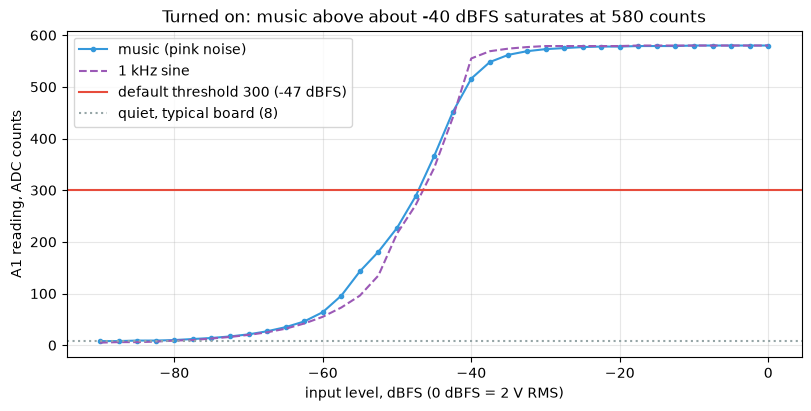

Default threshold 300 is crossed by music at -47.1 dBFS; saturated reading 580 counts

In [6]:
def settled_reading(wave_fn):
    circuit = fm.Circuit(fe)
    volts = circuit.feed(wave_fn(5.0))
    return int(fm.adc(volts[-20:]).mean())

t5 = np.arange(5 * fm.FS) / fm.FS
transfer = {"dbfs": TRANSFER_DBFS.tolist(), "pink": [], "sine": []}
for level in TRANSFER_DBFS:
    transfer["pink"].append(settled_reading(lambda s: fm.Source(np.random.default_rng(SEED), hum_mv=0.3).chunk(s, level, 0.0)))
    transfer["sine"].append(settled_reading(lambda s: fm.LINE_0DBFS * np.sqrt(2) * 10 ** (level / 20) * np.sin(2 * np.pi * 1000 * t5)))
crossing = float(np.interp(DEFAULT_T, transfer["pink"], TRANSFER_DBFS))
saturated = max(transfer["pink"])

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.plot(TRANSFER_DBFS, transfer["pink"], color=COLORS["level"], marker="o", markersize=3, label="music (pink noise)")
ax.plot(TRANSFER_DBFS, transfer["sine"], color=COLORS["sine"], linestyle="--", label="1 kHz sine")
ax.axhline(DEFAULT_T, color=COLORS["threshold"], label=f"default threshold {DEFAULT_T} ({crossing:.0f} dBFS)")
ax.axhline(8, color=COLORS["quiet"], linestyle=":", label="quiet, typical board (8)")
ax.set_xlabel("input level, dBFS (0 dBFS = 2 V RMS)")
ax.set_ylabel("A1 reading, ADC counts")
ax.set_title(f"Turned on: music above about -40 dBFS saturates at {saturated} counts")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
plt.show()
rprint(f"Default threshold {DEFAULT_T} is crossed by music at [cyan]{crossing:.1f} dBFS[/cyan]; "
       f"saturated reading [cyan]{saturated}[/cyan] counts")

**Conclusion - turned on.** Music crosses the default threshold 300 at -47 dBFS and saturates at 580 counts from about -40 dBFS up.

- **Mechanism** - stage 1 amplifies by 101 around VGND = 0.88 V, so 9 mV peak at the input already reaches 0 V on the negative side; louder music clips at 0 V and 3.5 V, and the rectifier input clamp at -0.6 V turns the reading into peak-to-peak minus 0.6 V, limited near 2.9 V by the LM324 output
- **Meaning** - at every normal listening level the reading is the same 575 to 580 counts; only quiet passages between -70 and -45 dBFS produce readings between quiet and saturation
- **Impact** - the 50 samples taken while learning on music spread by 0 to 7 counts, so a hysteresis of one sigma is 0 to 7 counts wide and changes nothing

## Scenarios

Each scenario streams through the circuit model in 10 s chunks and keeps the ADC reading every 51 ms. The readings are cached in `cache/`, so a re-run reads them back instead of recomputing.

In [7]:
def music_intervals(segments):
    t, out = 0.0, []
    for segment in segments:
        length = {"click": 0.5, "burst": segment[1]}.get(segment[0], segment[1])
        if segment[0] == "music":
            out.append((t, t + length))
        t += length
    return out


def synthesize(spec, seed, advance):
    board = BOARDS[spec["board"]]
    source = fm.Source(np.random.default_rng(seed), hum_mv=board["hum_mv"])
    circuit = fm.Circuit(fm.FrontEnd(ib=board["ib"]))
    volts = []
    for segment in spec["segments"]:
        kind = segment[0]
        if kind == "click":  # a transient on top of silence: peak volts, decay time constant
            wave = source.chunk(0.5)
            wave += fm.click(segment[1], 0.5, segment[2])
            volts.append(circuit.feed(wave))
            advance(0.5)
        elif kind == "burst":  # a short burst of full-level music
            volts.append(circuit.feed(source.chunk(segment[1], -6, 0.0)))
            advance(segment[1])
        else:
            level, spread = (segment[2], segment[3]) if kind == "music" else (None, 0.0)
            remaining = segment[1]
            while remaining > 0:
                step = min(10.0, remaining)
                volts.append(circuit.feed(source.chunk(step, level, spread)))
                advance(step)
                remaining -= step
    return fm.adc(np.concatenate(volts))

In [8]:
readings = {}
total = sum(sum({"click": 0.5}.get(s[0], s[1]) for s in spec["segments"]) for spec in SCENARIOS.values())
with Progress() as progress:
    task = progress.add_task("audio seconds", total=total)
    for i, (name, spec) in enumerate(SCENARIOS.items()):
        path = CACHE / f"{name.replace(' ', '_').replace(',', '')}.npy"
        length = sum({"click": 0.5}.get(s[0], s[1]) for s in spec["segments"])
        if path.exists():
            readings[name] = np.load(path)
            progress.advance(task, length)
        else:
            readings[name] = synthesize(spec, SEED + i, lambda s: progress.advance(task, s))
            np.save(path, readings[name])

Output()

## Firmware replay

Every scenario, setup and design runs through the firmware replica: 50-sample average, START above T after the 3 s settling time, audio on 3 s later, and off once 10 minutes pass without the timeout being restarted.

- **Learned setups** - the threshold and sigma come from the 50 readings that follow the learn time, as if the owner had pressed learn during that kind of music on an earlier day
- **Quiet level** - the idle average 15 s after power-on, before any music

In [9]:
def levels(design, setup, spec, counts, quiet):
    if setup == "default":
        threshold, sigma, learned, mean = DEFAULT_T, None, False, None
    else:
        k = int(spec["learn"][setup] / fm.ADC_PERIOD)
        window = counts[k:k + fm.SAMPLES]
        threshold, sigma = fm.learn(window)
        learned, mean = True, int(window.mean())
    if design == "original":
        return threshold, threshold
    if design == "sigma10":
        return threshold, fm.off_level(threshold, sigma if learned else threshold // 10)
    if design == "sigma25":
        return threshold, fm.off_level(threshold, sigma if learned else threshold // 4)
    if design == "quarter":
        return threshold, max(threshold // 4, fm.MIN_LEVEL)
    if design == "simple":
        threshold = max(mean // 2, SIMPLE_MIN_T) if learned else threshold
        return threshold, threshold // 4
    threshold = quiet + (mean - quiet) // 2 if learned else threshold
    return threshold, quiet + (threshold - quiet) // 4


def verdict(events, intervals):
    problems = []
    starts = [t for t, e in events if e == "START"]
    offs = [t for t, e in events if e == "OFF"]
    if intervals:
        first, last = intervals[0][0], intervals[-1][1]
        if not starts:
            problems.append("no START")
        elif starts[0] > first + 5:
            problems.append(f"START {starts[0] - first:.0f} s late")
        problems += [f"OFF during music at {t:.0f} s" for t in offs if t < last]
        on_at_end = [e for t, e in events if t < last][-1:] == ["START"]
        after = [t - last for t in offs if t >= last]
        if on_at_end and not after:
            problems.append("never OFF")
        elif after and not 540 <= after[0] <= 720:
            problems.append(f"OFF {after[0]:.0f} s after music")
    problems += [f"false START at {t:.0f} s" for t in starts if not any(s <= t <= e + 3 for s, e in intervals)]
    return problems


runs = []
with Progress() as progress:
    task = progress.add_task("firmware replays", total=sum(len(DESIGNS) * (1 + len(s["learn"])) for s in SCENARIOS.values()))
    for name, spec in SCENARIOS.items():
        counts = readings[name]
        average, _ = fm.run_firmware(counts, 10**6, 10**6)
        quiet = int(average[int(QUIET_AT / fm.ADC_PERIOD)])
        intervals = music_intervals(spec["segments"])
        for setup in ["default", *spec["learn"]]:
            for design in DESIGNS:
                threshold, off = levels(design, setup, spec, counts, quiet)
                _, events = fm.run_firmware(counts, threshold, off)
                runs.append(dict(scenario=name, setup=setup, design=design, threshold=int(threshold), off=int(off),
                                 quiet=quiet, events=[(round(t, 1), e) for t, e in events],
                                 problems=verdict(events, intervals)))
                progress.advance(task)

Output()

In [10]:
table = Table(title="Verdict per case (OK, or what went wrong)")
table.add_column("scenario / setup")
table.add_column("T", justify="right")
for design in DESIGNS:
    table.add_column(design)
for name, spec in SCENARIOS.items():
    for setup in ["default", *spec["learn"]]:
        row = [r for r in runs if r["scenario"] == name and r["setup"] == setup]
        cells = [("[green]OK[/green]" if not r["problems"] else f"[red]{'; '.join(r['problems'])}[/red]")
                 + f" [dim]off {r['off']}[/dim]" for r in row]
        table.add_row(f"{name} / {SETUPS[setup]}", str(row[0]["threshold"]), *cells)
rprint(table)

                                     Verdict per case (OK, or what went wrong)                                     
┏━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ scenario /    ┃     ┃               ┃               ┃               ┃              ┃               ┃            ┃
┃ setup         ┃   T ┃ original      ┃ sigma10       ┃ sigma25       ┃ quarter      ┃ simple        ┃ quiet      ┃
┡━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ pop / default │ 300 │ OK off 300    │ OK off 270    │ OK off 225    │ OK off 75    │ OK off 75     │ OK off 81  │
│ threshold 300 │     │               │               │               │              │               │            │
│ pop / learned │ 579 │ no START off  │ no START off  │ no START off  │ no START off │ OK off 72     │ OK off 79  │
│ on loud music │     │ 579           │ 579           │ 579           │ 144          │               │            │
│ classical /   │ 300 │ OK off 300    │ OK off 270    │ OK off 225    │ OK off 75    │ OK off 75     │ OK off 81  │
│ default       │     │               │               │               │              │               │            │
│ threshold 300 │     │               │               │               │              │               │            │
│ classical /   │ 576 │ START 31 s    │ START 31 s    │ START 31 s    │ START 31 s   │ OK off 72     │ OK off 79  │
│ learned on    │     │ late; OFF     │ late; OFF     │ late; OFF     │ late off 144 │               │            │
│ loud music    │     │ during music  │ during music  │ during music  │              │               │            │
│               │     │ at 908 s off  │ at 895 s off  │ at 895 s off  │              │               │            │
│               │     │ 576           │ 574           │ 574           │              │               │            │
│ classical /   │ 207 │ OK off 207    │ OK off 146    │ OK off 146    │ OK off 51    │ OK off 40     │ OK off 32  │
│ learned on    │     │               │               │               │              │               │            │
│ quiet music   │     │               │               │               │              │               │            │
│ late night /  │ 300 │ OFF during    │ OFF during    │ OFF during    │ OK off 75    │ OK off 75     │ OK off 81  │
│ default       │     │ music at 624  │ music at 624  │ music at 925  │              │               │            │
│ threshold 300 │     │ s off 300     │ s off 270     │ s off 225     │              │               │            │
│ late night /  │ 572 │ OFF during    │ OFF during    │ OFF during    │ OK off 143   │ OK off 71     │ OK off 78  │
│ learned on    │     │ music at 627  │ music at 627  │ music at 627  │              │               │            │
│ loud music    │     │ s off 572     │ s off 569     │ s off 569     │              │               │            │
│ late night /  │ 143 │ OK off 143    │ OK off 103    │ OK off 103    │ OK off 35    │ OK off 40     │ OK off 24  │
│ learned on    │     │               │               │               │              │               │            │
│ quiet music   │     │               │               │               │              │               │            │
│ clicks in     │ 300 │ OK off 300    │ OK off 270    │ OK off 225    │ OK off 75    │ OK off 75     │ OK off 81  │
│ silence /     │     │               │               │               │              │               │            │
│ default       │     │               │               │               │              │               │            │
│ threshold 300 │     │               │               │               │              │               │            │
│ late night,   │ 300 │ OFF during    │ OFF during    │ OFF during    │ OK off 75    │ OK off 75     │ OK off 100 │
│ worst board / │     │ music at 624  │ music at 624  │ 

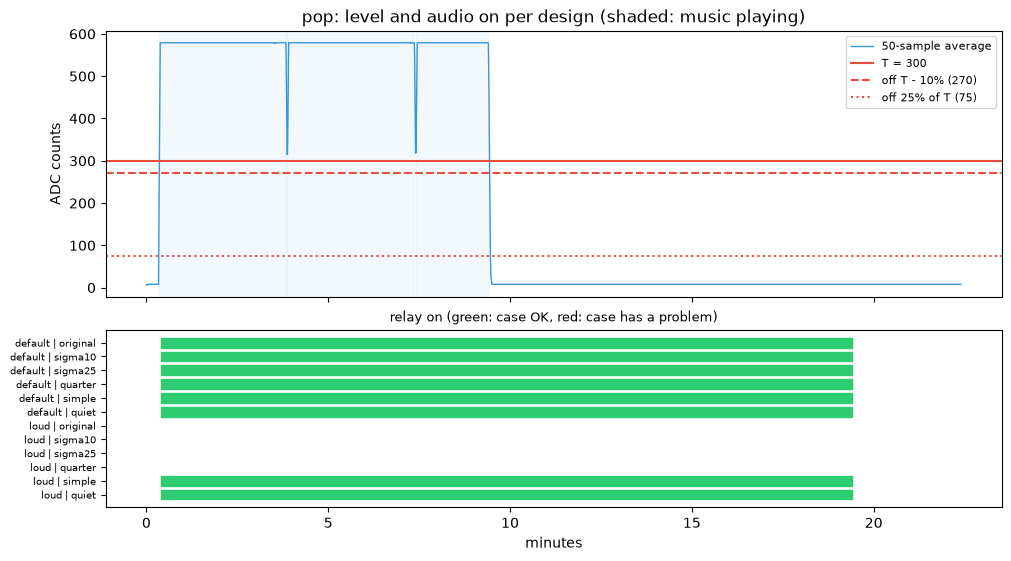

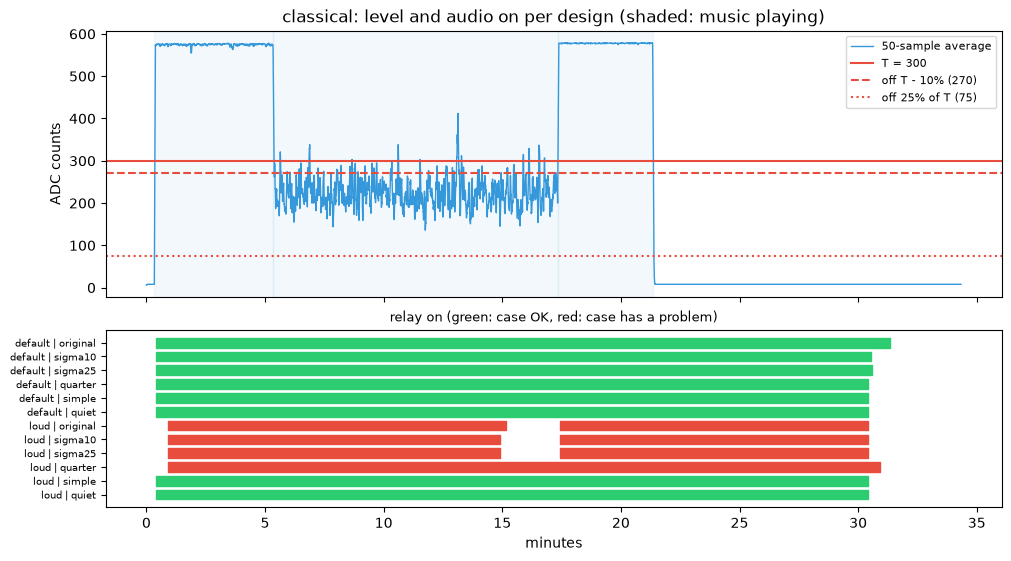

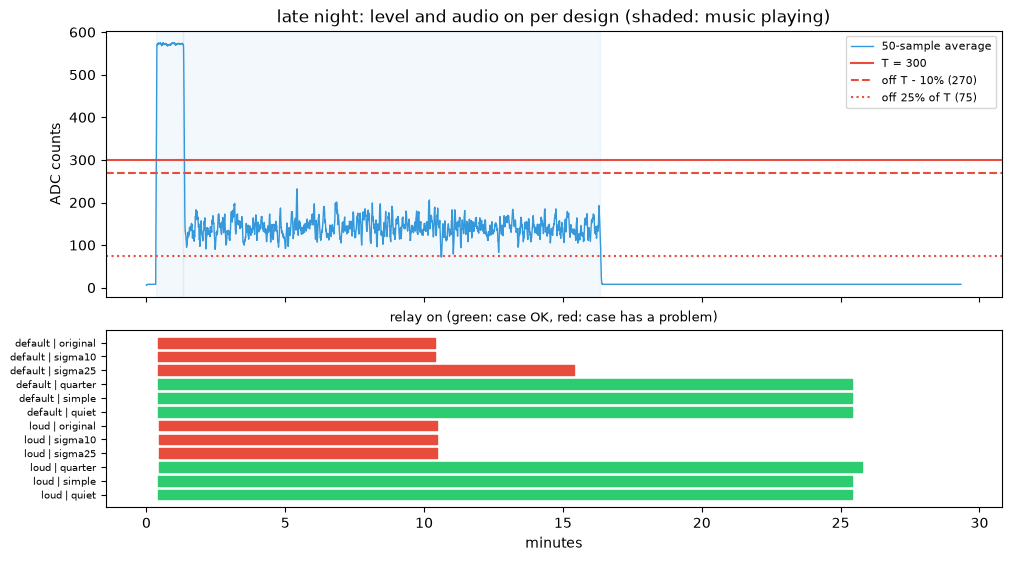

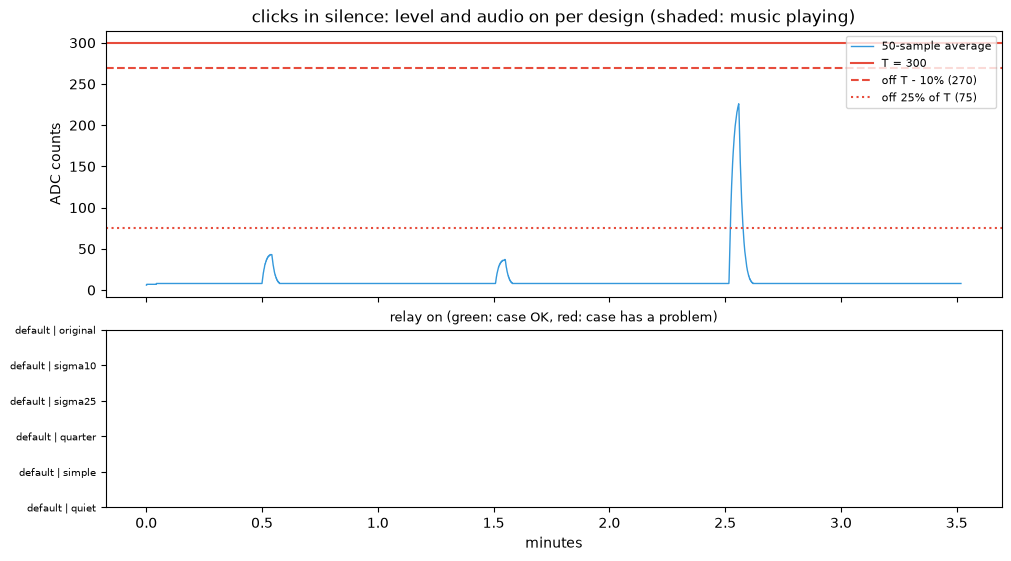

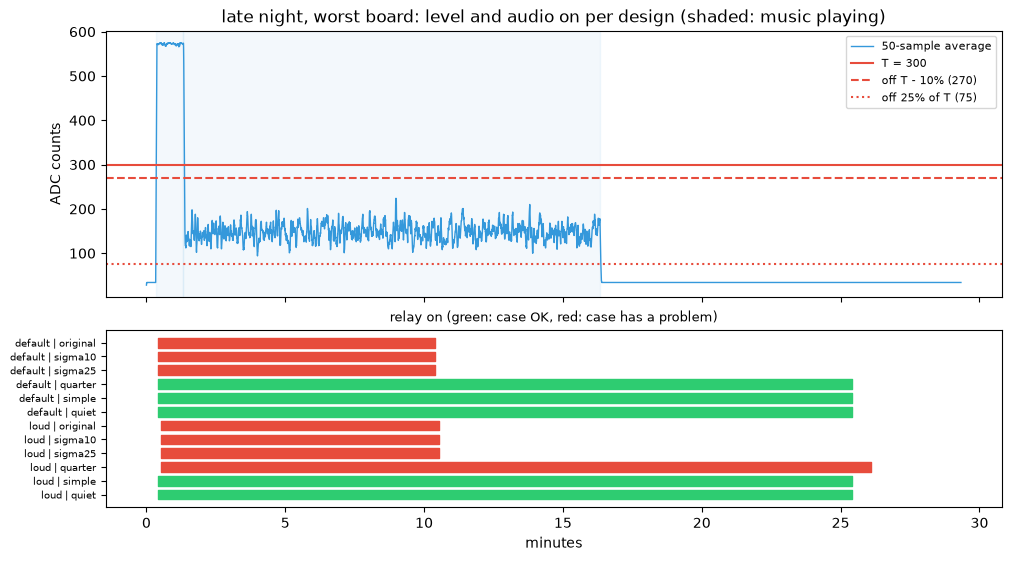

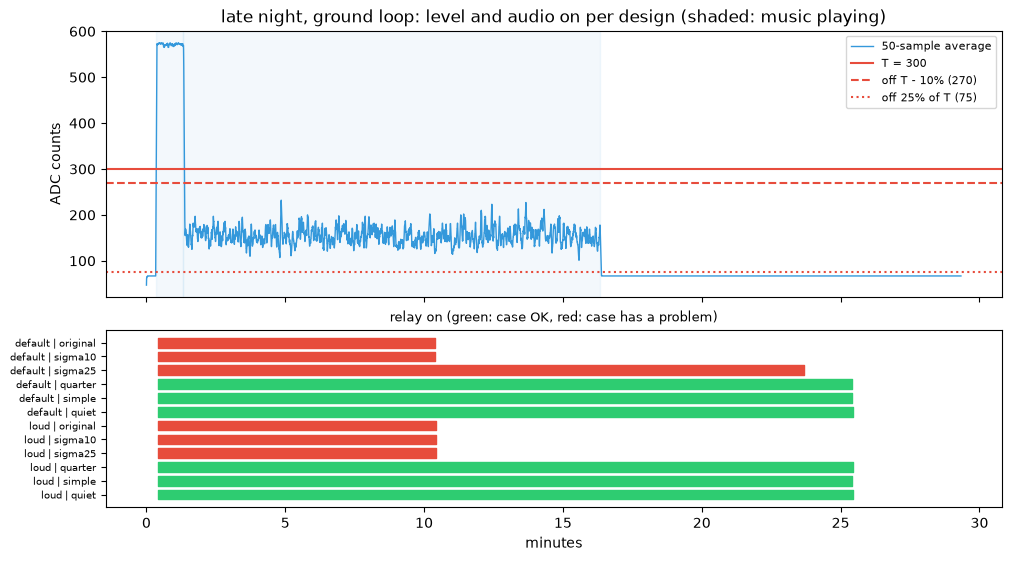

In [11]:
def timeline(name, setups=("default", "loud")):
    spec, counts = SCENARIOS[name], readings[name]
    average, _ = fm.run_firmware(counts, 10**6, 10**6)
    t = (np.arange(len(counts)) + 1) * fm.ADC_PERIOD / 60
    shown = [s for s in setups if s == "default" or s in spec["learn"]]
    fig, (ax, bars) = plt.subplots(2, 1, figsize=(10, 5.5), constrained_layout=True, sharex=True,
                                   gridspec_kw=dict(height_ratios=[3, 2]))
    ax.plot(t, average, color=COLORS["level"], linewidth=1, label="50-sample average")
    for s, e in music_intervals(spec["segments"]):
        ax.axvspan(s / 60, e / 60, color=COLORS["level"], alpha=0.06)
    default = {r["design"]: r for r in runs if r["scenario"] == name and r["setup"] == "default"}
    ax.axhline(default["original"]["threshold"], color=COLORS["threshold"], label="T = 300")
    ax.axhline(default["sigma10"]["off"], color=COLORS["threshold"], linestyle="--", label=f"off T - 10% ({default['sigma10']['off']})")
    ax.axhline(default["quarter"]["off"], color=COLORS["threshold"], linestyle=":", label=f"off 25% of T ({default['quarter']['off']})")
    ax.set_ylabel("ADC counts")
    ax.set_title(f"{name}: level and audio on per design (shaded: music playing)")
    ax.legend(loc="upper right", fontsize=8)
    rows = [(f"{setup[:7]} | {design}", r) for setup in shown for design in DESIGNS
            for r in runs if r["scenario"] == name and r["setup"] == setup and r["design"] == design]
    for i, (label, r) in enumerate(rows):
        on = None
        for time, event in r["events"] + [(t[-1] * 60, "END")]:
            if event == "START":
                on = time + fm.START_TIMEOUT
            elif on is not None:
                bars.broken_barh([(on / 60, (time - on) / 60)], (i - 0.35, 0.7),
                                 color=COLORS["on"] if not r["problems"] else COLORS["threshold"])
                on = None
    bars.set_yticks(range(len(rows)), [label for label, _ in rows], fontsize=7)
    bars.invert_yaxis()
    bars.set_xlabel("minutes")
    bars.set_title("relay on (green: case OK, red: case has a problem)", fontsize=9)
    plt.show()


for name in SCENARIOS:
    timeline(name)

**Conclusion - scenarios.** Six scenarios with up to three setups give 15 cases per design.

- **Off level close to T fails** - the original firmware and both T - sigma designs pass 7 of 15; at the default threshold the late-night case turns audio off at 624 s, 9 minutes after the music was turned down to -56 dBFS (reading about 140)
- **Learning on loud music sets T to the saturated reading** (572 to 579); every design that keeps the learned mean as T then starts late or never (pop: no START)
- **Off at 25% of T passes 11 of 15** - it keeps quiet listening on, but still inherits the learning problem
- **The simple design passes 14 of 15** - learn sets T to half the music reading (at least 160) and off is 25% of T; it fails only when a ground loop raises quiet to 67 counts and T was learned on quiet music (off 40, never OFF)
- **The quiet-based design passes 15 of 15** - its off level moves with the measured quiet reading
- **No design started audio from clicks** - a 2 V spike, a source pop and a 100 ms full-level burst all stay below 300 after the 50-sample average

## Replica check on simavr

The replica is only useful if it decides as the firmware does. The real `firmware.elf` (simple design: threshold 300, off level 75) runs on simavr with the whole pop scenario fed into A1, and its relay edges are compared with the replica's. The simavr run takes a few minutes, so its result is cached; delete `cache/simavr_check.json` after a firmware change.

In [12]:
check_path = CACHE / "simavr_check.json"
counts = readings[VALIDATE["scenario"]]
if check_path.exists():
    simavr_edges = json.loads(check_path.read_text())
else:
    image = eeprom.image((eeprom.NEC, 32, 0x20DF10EF), (eeprom.NEC, 32, 0x20DF906F), DEFAULT_T)
    board = sim.Board(eeprom=image)
    with Progress() as progress:
        task = progress.add_task("ADC samples on simavr", total=len(counts))
        for c in counts:
            board.set_audio(int(c))
            board.run(fm.ADC_PERIOD)
            progress.advance(task)
    simavr_edges = [(t / 1e6, level) for t, level in board.edges["relay"]]
    board.close()
    check_path.write_text(json.dumps(simavr_edges))

Relay edges: replica against firmware 
              on simavr               
┏━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ edge      ┃ replica, s ┃ simavr, s ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ relay on  │      24.32 │     24.62 │
│ relay off │    1164.59 │   1164.56 │
└───────────┴────────────┴───────────┘

Largest difference: 0.30 s

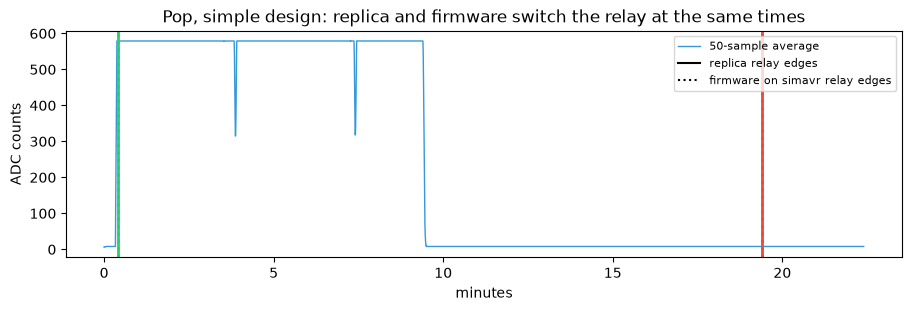

In [13]:
_, events = fm.run_firmware(counts, DEFAULT_T, DEFAULT_T // 4)
replica_edges = []
for t, e in events:
    replica_edges.append((round(t + fm.START_TIMEOUT, 2), 1) if e == "START" else (round(t, 2), 0))
simavr_rounded = [(round(t, 2), level) for t, level in simavr_edges]
worst = max(abs(a[0] - b[0]) for a, b in zip(replica_edges, simavr_rounded)) if len(replica_edges) == len(simavr_rounded) else None

table = Table(title="Relay edges: replica against firmware on simavr")
table.add_column("edge")
table.add_column("replica, s", justify="right")
table.add_column("simavr, s", justify="right")
for i in range(max(len(replica_edges), len(simavr_rounded))):
    r = replica_edges[i] if i < len(replica_edges) else ("-", "-")
    s = simavr_rounded[i] if i < len(simavr_rounded) else ("-", "-")
    table.add_row("relay on" if (r[1] if r[1] != "-" else s[1]) == 1 else "relay off", str(r[0]), str(s[0]))
rprint(table)
rprint(f"Largest difference: [cyan]{worst:.2f} s[/cyan]" if worst is not None else "[red]edge counts differ[/red]")

average, _ = fm.run_firmware(counts, 10**6, 10**6)
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
t = (np.arange(len(counts)) + 1) * fm.ADC_PERIOD / 60
ax.plot(t, average, color=COLORS["level"], linewidth=1, label="50-sample average")
for edges, style, label in ((replica_edges, "-", "replica"), (simavr_rounded, ":", "firmware on simavr")):
    for time, level in edges:
        ax.axvline(time / 60, color=COLORS["on"] if level else COLORS["threshold"], linestyle=style, linewidth=2)
    ax.plot([], [], color="black", linestyle=style, label=f"{label} relay edges")
ax.set_xlabel("minutes")
ax.set_ylabel("ADC counts")
ax.set_title("Pop, simple design: replica and firmware switch the relay at the same times")
ax.legend(loc="upper right", fontsize=8)
plt.show()

**Conclusion - replica check.** The replica and the firmware switch the relay within 0.30 s of each other over the whole pop scenario (on at 24.32 s and 24.62 s, off at 1164.59 s and 1164.56 s).

- **Mechanism** - the difference is the phase between the replica's sample clock and the firmware's millis()
- **Meaning** - the replica's verdicts on the other designs hold for the firmware
- **Impact** - the simple design now in the firmware turns audio off 601 s after the music ends at 564 s, as the replica predicts

## Export

The explainer page reads one JSON file: the transfer curve, the quiet readings, a one-per-second trace of each scenario's average, and every case's levels, events and problems.

In [14]:
export = dict(
    transfer=transfer, floor=floor, default_threshold=DEFAULT_T, crossing_dbfs=round(crossing, 1), saturated=saturated,
    scenarios={name: dict(board=spec["board"], music=music_intervals(spec["segments"]),
                          average=fm.run_firmware(readings[name], 10**6, 10**6)[0][::20].astype(int).tolist(),
                          step_s=round(20 * fm.ADC_PERIOD, 3))
               for name, spec in SCENARIOS.items()},
    designs=DESIGNS, setups=SETUPS, runs=runs,
    check=dict(replica=replica_edges, simavr=simavr_rounded),
)
(RESULTS / "audio-level-simulation.json").write_text(json.dumps(export))
rprint(f"Wrote [cyan]{RESULTS / 'audio-level-simulation.json'}[/cyan], {len(runs)} cases")

Wrote results/audio-level-simulation.json, 90 cases

## Summary

The grid counts, per design, the cases that ended without a problem. A case is one scenario with one setup.

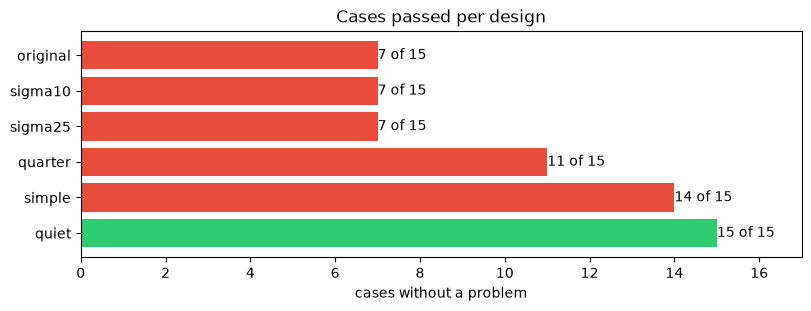

In [15]:
ok = {d: sum(1 for r in runs if r["design"] == d and not r["problems"]) for d in DESIGNS}
cases = sum(1 for r in runs if r["design"] == "original")
fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.barh(list(DESIGNS), [ok[d] for d in DESIGNS], color=[COLORS["on"] if ok[d] == cases else COLORS["threshold"] for d in DESIGNS])
for i, d in enumerate(DESIGNS):
    ax.annotate(f"{ok[d]} of {cases}", (ok[d], i), va="center", ha="left")
ax.set_xlim(0, cases + 2)
ax.invert_yaxis()
ax.set_xlabel("cases without a problem")
ax.set_title("Cases passed per design")
plt.show()

**Conclusion - summary.** This front end produces three bands: quiet (4 to 35 counts, 67 with a ground loop), quiet music (20 to 300) and loud music (575 to 580, saturated).

- **Mechanism** - a hysteresis works only when the off level sits just above quiet and the threshold sits below the music it was learned on
- **Meaning** - the one-sigma rule does not make sense on this board; an off level at 25% of T does, once learning stops setting T to the music's mean
- **Impact** - the simple design fixes both with two lines of arithmetic and passes 14 of 15 cases; measuring quiet on the board closes the last case at the cost of a tracked quiet level